# Battery State of Health prediction with SVM

This notebook predicts battery State of Health (SoH) from the prepared NASA battery cycle files. It uses `metadata.csv` for discharge capacities and `tmp/*.csv` for measured discharge time series, following the Support Vector Regression approach in `SVM.py`.

Run the notebook from the repository root, where `metadata.csv` and the `tmp/` directory are located. The evaluation holds out an entire battery, so test-battery cycles do not leak into model training or parameter selection. SoH is calculated as `capacity / that battery's first discharge capacity * 100`.

Required packages: `numpy`, `pandas`, `matplotlib`, and `scikit-learn`.

## 1. Imports and paths

If your generated files are stored elsewhere, update `BASE_DIR` below. Paths are relative to the directory from which Jupyter was started.

In [2]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupShuffleSplit, LeaveOneGroupOut
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

BASE_DIR = Path.cwd()
METADATA_PATH = BASE_DIR / "metadata.csv"
CYCLE_DATA_DIR = BASE_DIR / "tmp"

if not METADATA_PATH.is_file():
    raise FileNotFoundError(
        f"Could not find {METADATA_PATH}. Start Jupyter from the repository root "
        "or update BASE_DIR to the folder containing metadata.csv."
    )
if not CYCLE_DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Could not find {CYCLE_DATA_DIR}. Update CYCLE_DATA_DIR to the folder "
        "containing the prepared cycle CSV files."
    )

print(f"Metadata: {METADATA_PATH}")
print(f"Cycle CSV directory: {CYCLE_DATA_DIR}")

Metadata: c:\Users\prshi\OneDrive\Desktop\SOH-prediction-using-NASA-Dataset-master\SOH-prediction-using-NASA-Dataset-master\metadata.csv
Cycle CSV directory: c:\Users\prshi\OneDrive\Desktop\SOH-prediction-using-NASA-Dataset-master\SOH-prediction-using-NASA-Dataset-master\tmp


## 2. Load discharge-cycle metadata

The metadata supplies the measured capacity label for each discharge operation. Capacity is reserved for constructing the target and is never included among the model input features.

In [3]:
metadata = pd.read_csv(METADATA_PATH)
required_columns = {"type", "battery_id", "test_id", "filename", "Capacity"}
missing_columns = required_columns.difference(metadata.columns)
if missing_columns:
    raise ValueError(f"metadata.csv is missing required columns: {sorted(missing_columns)}")

discharge_metadata = metadata.loc[
    metadata["type"].astype(str).str.lower().eq("discharge"),
    ["battery_id", "test_id", "filename", "Capacity"],
].copy()
discharge_metadata["Capacity"] = pd.to_numeric(discharge_metadata["Capacity"], errors="coerce")
discharge_metadata["test_id"] = pd.to_numeric(discharge_metadata["test_id"], errors="coerce")
discharge_metadata = discharge_metadata.dropna(subset=["battery_id", "test_id", "filename", "Capacity"])
discharge_metadata = discharge_metadata.sort_values(["battery_id", "test_id"]).reset_index(drop=True)

if discharge_metadata.empty:
    raise ValueError("No discharge rows with valid battery IDs, test IDs, filenames, and capacities were found.")

missing_files = [
    filename for filename in discharge_metadata["filename"].astype(str)
    if not (CYCLE_DATA_DIR / Path(filename).name).is_file()
]
if missing_files:
    raise FileNotFoundError(
        f"Missing {len(missing_files)} discharge CSV file(s) in {CYCLE_DATA_DIR}; "
        f"examples: {missing_files[:5]}"
    )

print(f"Discharge cycles: {len(discharge_metadata)}")
print(f"Batteries: {sorted(discharge_metadata['battery_id'].unique())}")
display(discharge_metadata.head())

Discharge cycles: 636
Batteries: ['B0005', 'B0006', 'B0007', 'B0018']


,battery_id,test_id,filename,Capacity
0,B0005,1,00002.csv,1.856487
1,B0005,3,00004.csv,1.846327
2,B0005,5,00006.csv,1.835349
3,B0005,7,00008.csv,1.835263
4,B0005,9,00010.csv,1.834646


## 3. Convert each discharge time series into cycle features

For each numeric measurement in a discharge CSV, calculate mean, standard deviation, minimum, maximum, first, and last values. These summaries provide a fixed-size feature row per cycle; `Capacity` is not read from the cycle CSV or used as a feature.

In [4]:
def summarize_discharge_csv(csv_path):
    """Return numeric summary features for one prepared discharge-cycle CSV."""
    cycle = pd.read_csv(csv_path)
    numeric_cycle = cycle.select_dtypes(include="number")
    if numeric_cycle.empty:
        raise ValueError(f"No numeric measurement columns found in {csv_path}")
    if cycle.empty:
        raise ValueError(f"The cycle CSV has no measurement rows: {csv_path}")

    summary = {}
    for column in numeric_cycle.columns:
        values = numeric_cycle[column]
        safe_column = str(column).strip().replace(" ", "_")
        summary[f"feature__{safe_column}__mean"] = values.mean()
        summary[f"feature__{safe_column}__std"] = values.std(ddof=0)
        summary[f"feature__{safe_column}__min"] = values.min()
        summary[f"feature__{safe_column}__max"] = values.max()
        summary[f"feature__{safe_column}__first"] = values.iloc[0]
        summary[f"feature__{safe_column}__last"] = values.iloc[-1]
    return summary


feature_rows = []
for row in discharge_metadata.itertuples(index=False):
    csv_path = CYCLE_DATA_DIR / Path(str(row.filename)).name
    features = summarize_discharge_csv(csv_path)
    features["battery_id"] = str(row.battery_id)
    features["test_id"] = row.test_id
    features["Capacity"] = row.Capacity
    feature_rows.append(features)

cycle_data = pd.DataFrame(feature_rows)
print(f"Feature table shape: {cycle_data.shape}")
display(cycle_data.head())

Feature table shape: (636, 39)


,feature__Voltage_measured__mean,feature__Voltage_measured__std,feature__Voltage_measured__min,feature__Voltage_measured__max,feature__Voltage_measured__first,feature__Voltage_measured__last,feature__Current_measured__mean,feature__Current_measured__std,feature__Current_measured__min,feature__Current_measured__max,...,feature__Voltage_load__last,feature__Time__mean,feature__Time__std,feature__Time__min,feature__Time__max,feature__Time__first,feature__Time__last,battery_id,test_id,Capacity
0,3.529829,0.235957,2.612467,4.191492,4.191492,3.277170,-1.818702,0.593546,-2.018015,0.000729,...,0.0,1812.087497,1066.555257,0.0,3690.234,0.0,3690.234,B0005,1,1.856487
1,3.537320,0.234765,2.587209,4.189773,4.189773,3.300245,-1.817560,0.595180,-2.016821,0.002927,...,0.0,1803.143372,1061.452334,0.0,3672.344,0.0,3672.344,B0005,3,1.846327
2,3.543737,0.227525,2.651917,4.188187,4.188187,3.327451,-1.816487,0.596498,-2.016574,0.001484,...,0.0,1793.809379,1055.695023,0.0,3651.641,0.0,3651.641,B0005,5,1.835349
3,3.543666,0.232744,2.592948,4.188461,4.188461,3.314182,-1.825589,0.583462,-2.015936,0.001547,...,0.0,1784.359428,1050.094050,0.0,3631.563,0.0,3631.563,B0005,7,1.835263
4,3.542343,0.236689,2.547420,4.188299,4.188299,3.305497,-1.826114,0.583469,-2.017426,0.001701,...,0.0,1783.501351,1049.391942,0.0,3629.172,0.0,3629.172,B0005,9,1.834646


## 4. Build the SoH target and inspect the dataset

Within each battery, cycles are ordered by `test_id`. The first recorded discharge capacity is used as that battery's reference capacity. Battery ID is retained only for grouping and reporting, not as a predictor.

In [5]:
cycle_data = cycle_data.sort_values(["battery_id", "test_id"]).reset_index(drop=True)
cycle_data["cycle_number"] = cycle_data.groupby("battery_id").cumcount() + 1
reference_capacity = cycle_data.groupby("battery_id")["Capacity"].transform("first")
if (reference_capacity <= 0).any():
    raise ValueError("Every battery must have a positive first discharge capacity to calculate SoH.")
cycle_data["SoH_percent"] = cycle_data["Capacity"] / reference_capacity * 100.0

feature_columns = [column for column in cycle_data.columns if column.startswith("feature__")]
feature_columns.append("cycle_number")
target_column = "SoH_percent"
required_model_columns = feature_columns + [target_column, "battery_id"]
model_data = cycle_data[required_model_columns].replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

if model_data["battery_id"].nunique() < 2:
    raise ValueError("At least two batteries are required for a battery-held-out evaluation.")
if model_data.empty:
    raise ValueError("No complete model rows remain after removing invalid feature or target values.")

print(f"Usable cycles: {len(model_data)}")
print(f"Input features: {len(feature_columns)}")
display(model_data.groupby("battery_id")["SoH_percent"].agg(["count", "min", "max"]))
display(model_data.head())

Usable cycles: 636
Input features: 37


,count,min,max
battery_id,,,
B0005,168,69.348842,100.0
B0006,168,56.689285,100.0
B0007,168,74.056928,100.0
B0018,132,72.293702,100.0


,feature__Voltage_measured__mean,feature__Voltage_measured__std,feature__Voltage_measured__min,feature__Voltage_measured__max,feature__Voltage_measured__first,feature__Voltage_measured__last,feature__Current_measured__mean,feature__Current_measured__std,feature__Current_measured__min,feature__Current_measured__max,...,feature__Voltage_load__last,feature__Time__mean,feature__Time__std,feature__Time__min,feature__Time__max,feature__Time__first,feature__Time__last,cycle_number,SoH_percent,battery_id
0,3.529829,0.235957,2.612467,4.191492,4.191492,3.277170,-1.818702,0.593546,-2.018015,0.000729,...,0.0,1812.087497,1066.555257,0.0,3690.234,0.0,3690.234,1,100.000000,B0005
1,3.537320,0.234765,2.587209,4.189773,4.189773,3.300245,-1.817560,0.595180,-2.016821,0.002927,...,0.0,1803.143372,1061.452334,0.0,3672.344,0.0,3672.344,2,99.452721,B0005
2,3.543737,0.227525,2.651917,4.188187,4.188187,3.327451,-1.816487,0.596498,-2.016574,0.001484,...,0.0,1793.809379,1055.695023,0.0,3651.641,0.0,3651.641,3,98.861386,B0005
3,3.543666,0.232744,2.592948,4.188461,4.188461,3.314182,-1.825589,0.583462,-2.015936,0.001547,...,0.0,1784.359428,1050.094050,0.0,3631.563,0.0,3631.563,4,98.856718,B0005
4,3.542343,0.236689,2.547420,4.188299,4.188299,3.305497,-1.826114,0.583469,-2.017426,0.001701,...,0.0,1783.501351,1049.391942,0.0,3629.172,0.0,3629.172,5,98.823482,B0005


In [6]:
model_data[model_data["battery_id"] == "B0007"]

,feature__Voltage_measured__mean,feature__Voltage_measured__std,feature__Voltage_measured__min,feature__Voltage_measured__max,feature__Voltage_measured__first,feature__Voltage_measured__last,feature__Current_measured__mean,feature__Current_measured__std,feature__Current_measured__min,feature__Current_measured__max,...,feature__Voltage_load__last,feature__Time__mean,feature__Time__std,feature__Time__min,feature__Time__max,feature__Time__first,feature__Time__last,cycle_number,SoH_percent,battery_id
336,3.522007,0.287445,2.145976,4.199497,4.199360,3.062113,-1.869119,0.475297,-1.996867,0.000910,...,0.000,1812.087497,1066.555257,0.0,3690.234,0.0,3690.234,1,100.000000,B0007
337,3.531949,0.279709,2.111017,4.198510,4.198257,3.079226,-1.868042,0.476600,-1.994391,0.003602,...,0.000,1803.143372,1061.452334,0.0,3672.344,0.0,3672.344,2,99.449234,B0007
338,3.534403,0.283727,2.025109,4.198280,4.198280,3.063266,-1.877785,0.458417,-1.994682,-0.001028,...,0.000,1793.809379,1055.695023,0.0,3651.641,0.0,3651.641,3,99.450590,B0007
339,3.534925,0.290087,1.922542,4.198267,4.197942,3.039421,-1.887526,0.439224,-1.995273,-0.000698,...,0.000,1784.359428,1050.094050,0.0,3631.563,0.0,3631.563,4,99.456314,B0007
340,3.534537,0.292206,1.871159,4.198464,4.198464,3.043167,-1.887156,0.439454,-1.993550,0.000598,...,0.000,1783.501351,1049.391942,0.0,3629.172,0.0,3629.172,5,99.386510,B0007
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499,3.462081,0.273382,2.132719,4.199394,4.199365,3.418468,-1.842240,0.520537,-1.993238,0.000995,...,0.001,1388.981387,806.073763,0.0,2793.390,0.0,2793.390,164,74.359204,B0007
500,3.457878,0.281469,2.011476,4.198995,4.198809,3.410207,-1.842253,0.520542,-1.992953,0.002778,...,0.001,1389.304451,806.012210,0.0,2793.390,0.0,2793.390,165,74.367898,B0007
501,3.461591,0.271129,2.161046,4.198422,4.198422,3.428899,-1.835606,0.531115,-1.997555,0.001703,...,0.001,1388.685185,805.766164,0.0,2792.485,0.0,2792.485,166,74.056928,B0007
502,3.462906,0.281636,2.014355,4.188887,4.188843,3.372148,-1.856101,0.497405,-1.993315,0.000514,...,0.001,1393.789745,808.502556,0.0,2802.016,0.0,2802.016,167,75.184938,B0007


In [7]:
model_data[model_data["battery_id"] == "B0006"]

,feature__Voltage_measured__mean,feature__Voltage_measured__std,feature__Voltage_measured__min,feature__Voltage_measured__max,feature__Voltage_measured__first,feature__Voltage_measured__last,feature__Current_measured__mean,feature__Current_measured__std,feature__Current_measured__min,feature__Current_measured__max,...,feature__Voltage_load__last,feature__Time__mean,feature__Time__std,feature__Time__min,feature__Time__max,feature__Time__first,feature__Time__last,cycle_number,SoH_percent,battery_id
168,3.556946,0.226019,2.475768,4.179823,4.179800,2.475768,-1.990533,0.201498,-2.015538,0.000434,...,1.653,1812.087497,1066.555257,0.0,3690.234,0.0,3690.234,1,100.000000,B0006
169,3.561476,0.231415,2.351526,4.177288,4.177288,2.351526,-1.990278,0.201909,-2.014902,-0.000208,...,1.543,1803.143372,1061.452334,0.0,3672.344,0.0,3672.344,2,99.498985,B0006
170,3.566752,0.223549,2.440480,4.178121,4.177795,2.440480,-1.989947,0.202473,-2.014434,-0.000658,...,1.650,1793.809379,1055.695023,0.0,3651.641,0.0,3651.641,3,98.918547,B0006
171,3.568795,0.220979,2.479156,4.178562,4.178370,2.479156,-1.989601,0.202976,-2.014205,0.000198,...,1.690,1784.359428,1050.094050,0.0,3631.563,0.0,3631.563,4,98.916498,B0006
172,3.563971,0.235035,2.280188,4.178250,4.178016,2.280188,-1.989548,0.202794,-2.013996,-0.001142,...,1.488,1783.501351,1049.391942,0.0,3629.172,0.0,3629.172,5,98.289755,B0006
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
331,3.414810,0.256762,2.481190,4.169704,4.169704,3.696327,-1.516972,0.864747,-2.019273,0.002248,...,0.000,1388.981387,806.073763,0.0,2793.390,0.0,2793.390,164,56.689285,B0006
332,3.416618,0.257869,2.491537,4.180284,4.180284,3.697170,-1.523850,0.860389,-2.014626,0.002022,...,0.000,1389.304451,806.012210,0.0,2793.390,0.0,2793.390,165,57.209230,B0006
333,3.412134,0.263727,2.409041,4.181170,4.181158,3.696674,-1.523793,0.860433,-2.016243,0.000366,...,0.000,1388.685185,805.766164,0.0,2792.485,0.0,2792.485,166,56.933921,B0006
334,3.419700,0.252911,2.475768,4.157552,4.157545,3.693059,-1.539131,0.851192,-2.013736,-0.000424,...,0.000,1393.789745,808.502556,0.0,2802.016,0.0,2802.016,167,57.728747,B0006


## 5. Hold out one battery and tune an RBF Support Vector Regressor

A random row split can make evaluation optimistic because cycles from the same battery appear in both sets. Instead, `GroupShuffleSplit` reserves a complete battery for the final test. Grid search uses leave-one-battery-out folds among the training batteries only. Scaling is part of the pipeline so each validation fold learns its own scaler.

In [9]:
X = model_data[feature_columns]
y = model_data[target_column]
groups = model_data["battery_id"]

outer_split = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_indices, test_indices = next(outer_split.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_indices], X.iloc[test_indices]
y_train, y_test = y.iloc[train_indices], y.iloc[test_indices]
groups_train = groups.iloc[train_indices]
groups_test = groups.iloc[test_indices]

if groups_train.nunique() < 2:
    raise ValueError("At least two training batteries are required for grouped parameter tuning.")

pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("svr", SVR(kernel="rbf")),
])
parameter_grid = {
    "svr__C": [1, 10, 100],
    "svr__epsilon": [0.01, 0.1, 1.0],
    "svr__gamma": ["scale", 0.01, 0.1],
}
group_cv = LeaveOneGroupOut()
search = GridSearchCV(
    estimator=pipeline,
    param_grid=parameter_grid,
    scoring="neg_mean_absolute_error",
    cv=group_cv,
    n_jobs=-1,
    refit=True,
)
search.fit(X_train, y_train, groups=groups_train)
best_model = search.best_estimator_

print(f"Training batteries: {sorted(groups_train.unique())}")
print(f"Held-out test battery/batteries: {sorted(groups_test.unique())}")
print(f"Best parameters: {search.best_params_}")
print(f"Best grouped CV MAE: {-search.best_score_:.3f} percentage points")

Training batteries: ['B0005', 'B0007', 'B0018']
Held-out test battery/batteries: ['B0006']
Best parameters: {'svr__C': 100, 'svr__epsilon': 0.01, 'svr__gamma': 0.01}
Best grouped CV MAE: 3.193 percentage points


## 6. Evaluate predictions on the held-out battery

MAE and RMSE are reported in SoH percentage points. R² is included for completeness, but should be interpreted cautiously when the test set contains only one battery.

In [10]:
y_pred = best_model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
metrics = pd.DataFrame([{
    "test_batteries": ", ".join(sorted(groups_test.unique())),
    "MAE_percentage_points": mean_absolute_error(y_test, y_pred),
    "RMSE_percentage_points": rmse,
    "R2": r2_score(y_test, y_pred) if len(y_test) > 1 else np.nan,
}])

predictions = model_data.iloc[test_indices][["battery_id", "cycle_number", "SoH_percent"]].copy()
predictions = predictions.rename(columns={"SoH_percent": "SoH_actual_percent"})
predictions["SoH_predicted_percent"] = y_pred
predictions["absolute_error_percentage_points"] = np.abs(
    predictions["SoH_actual_percent"] - predictions["SoH_predicted_percent"]
)
predictions = predictions.sort_values(["battery_id", "cycle_number"]).reset_index(drop=True)

display(metrics.round(4))
display(predictions.head(10).round(3))

,test_batteries,MAE_percentage_points,RMSE_percentage_points,R2
0,B0006,7.271,7.6902,0.612


,battery_id,cycle_number,SoH_actual_percent,SoH_predicted_percent,absolute_error_percentage_points
0,B0006,1,100.000,99.804,0.196
1,B0006,2,99.499,99.203,0.296
2,B0006,3,98.919,98.920,0.001
3,B0006,4,98.916,98.873,0.044
4,B0006,5,98.290,99.201,0.911
5,B0006,6,98.947,101.780,2.834
6,B0006,7,98.907,101.865,2.958
7,B0006,8,96.730,97.895,1.164
8,B0006,9,96.700,97.326,0.626
9,B0006,10,96.162,98.009,1.846


## 7. Plot actual and predicted SoH

This plot shows the held-out battery's measured target and model predictions across discharge-cycle order.

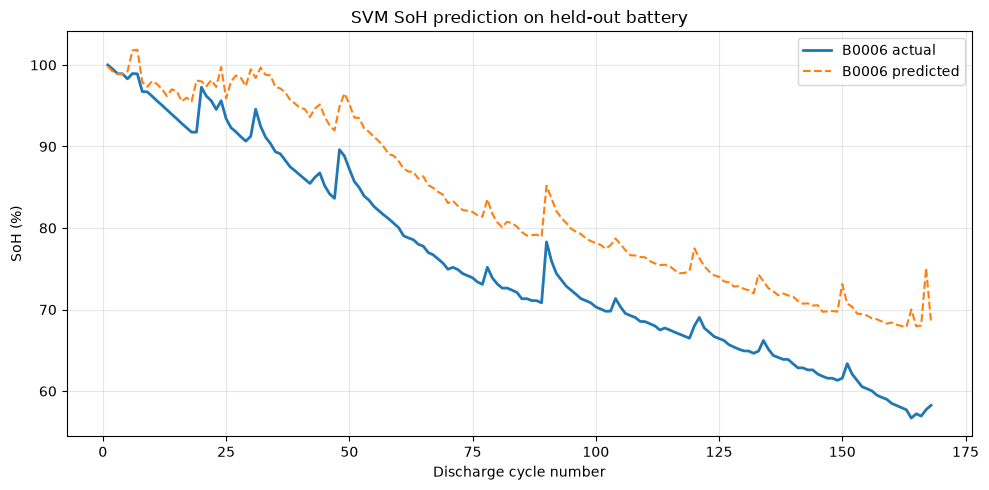

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
for battery_id, battery_predictions in predictions.groupby("battery_id"):
    ax.plot(
        battery_predictions["cycle_number"],
        battery_predictions["SoH_actual_percent"],
        label=f"{battery_id} actual",
        linewidth=2,
    )
    ax.plot(
        battery_predictions["cycle_number"],
        battery_predictions["SoH_predicted_percent"],
        "--",
        label=f"{battery_id} predicted",
    )

ax.set(title="SVM SoH prediction on held-out battery", xlabel="Discharge cycle number", ylabel="SoH (%)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 8. Optional: save held-out predictions

Set `SAVE_PREDICTIONS` to `True` to write the evaluation table to the repository root. The saved file contains held-out battery results, not training predictions.

In [12]:
SAVE_PREDICTIONS = False
PREDICTIONS_PATH = BASE_DIR / "svm_soh_predictions.csv"

if SAVE_PREDICTIONS:
    predictions.to_csv(PREDICTIONS_PATH, index=False)
    print(f"Saved held-out predictions to {PREDICTIONS_PATH}")
else:
    print("Prediction export is off. Set SAVE_PREDICTIONS = True to save the CSV.")

Prediction export is off. Set SAVE_PREDICTIONS = True to save the CSV.


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("mean_absolute_error: ", mean_absolute_error(y_test, y_pred))
print("mean_squared_error: ", mean_squared_error(y_test, y_pred))
print("r2_score: ", r2_score(y_test, y_pred))

mean_absolute_error:  7.27097757013595
mean_squared_error:  59.13845196045263
r2_score:  0.6120250644417329
